<a href="https://colab.research.google.com/github/RealHotnCold/MLA0204-192511036/blob/main/20_Implement_Future_Sales_Prediction_using_a_suitable_machine_learning_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Import Libraries and Generate Synthetic Sales Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Generate realistic synthetic daily sales data
np.random.seed(42)
dates = pd.date_range(start="2023-01-01", end="2023-12-31", freq="D")
n_days = len(dates)

# Features: TV advertising budget, Radio budget, Social Media budget, and Markdown discount
tv_budget = np.random.uniform(10, 100, n_days)
radio_budget = np.random.uniform(5, 50, n_days)
social_budget = np.random.uniform(2, 30, n_days)
is_weekend = (dates.dayofweek >= 5).astype(int)

# Sales calculation with some noise and non-linear relationships
sales = (15 + 0.5 * tv_budget + 0.8 * radio_budget + 1.2 * social_budget
         + 15 * is_weekend + np.random.normal(0, 5, n_days))

# Create DataFrame
df = pd.DataFrame({
    'Date': dates,
    'TV_Budget': tv_budget,
    'Radio_Budget': radio_budget,
    'Social_Budget': social_budget,
    'Is_Weekend': is_weekend,
    'Sales': sales
})

display(df.head())

,Date,TV_Budget,Radio_Budget,Social_Budget,Is_Weekend,Sales
0,2023-01-01,43.708611,22.374619,6.599442,1,75.085663
1,2023-01-02,95.564288,48.253575,24.808092,0,128.160093
2,2023-01-03,75.879455,45.740779,20.625522,0,117.059861
3,2023-01-04,63.879264,13.810601,16.645832,0,74.848758
4,2023-01-05,24.041678,8.121259,12.047254,0,45.494705


### 2. Preprocess Data and Train-Test Split

In [2]:
# Extract temporal features
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

# Define Features and Target
X = df[['TV_Budget', 'Radio_Budget', 'Social_Budget', 'Is_Weekend', 'Month', 'Day']]
y = df['Sales']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (292, 6)
Testing set shape: (73, 6)


### 3. Model Training & Evaluation

In [3]:
# Train a Random Forest Regressor
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 45.78
R-squared (R2) Score: 0.8930


### 4. Plot Actual vs. Predicted Sales

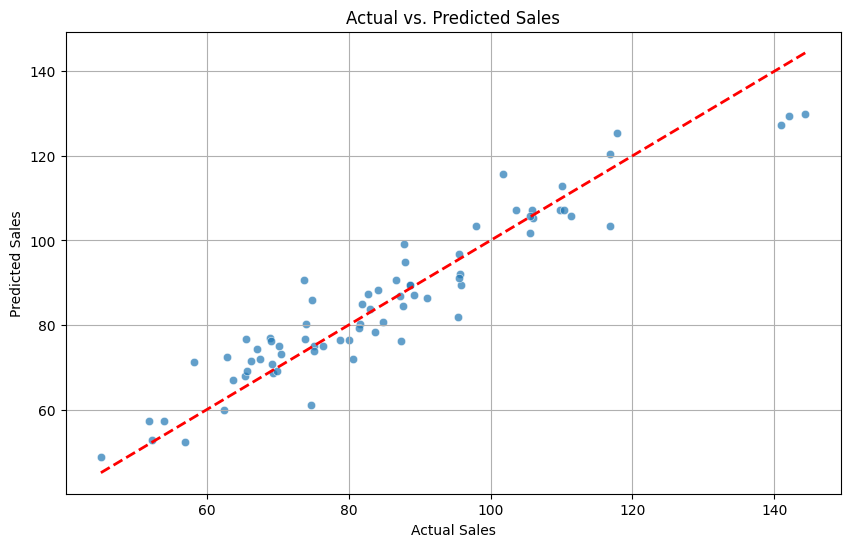

In [4]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted Sales')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.grid(True)
plt.show()